In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [3]:
df = pd.read_csv("house_prices.csv")

print("Dataset Shape:", df.shape)

display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (300, 8)


,Property_ID,Area,Bedrooms,Bathrooms,Age,Location,Property_Type,Price
0,PROP0001,3712,4,3,36,Rural,House,22260000
1,PROP0002,1591,4,1,35,Suburb,House,16057500
2,PROP0003,1646,4,3,20,Rural,Villa,12730000
3,PROP0004,4814,1,2,13,City Center,Villa,50840000
4,PROP0005,800,4,2,38,Suburb,Apartment,10650000



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Property_ID    300 non-null    str  
 1   Area           300 non-null    int64
 2   Bedrooms       300 non-null    int64
 3   Bathrooms      300 non-null    int64
 4   Age            300 non-null    int64
 5   Location       300 non-null    str  
 6   Property_Type  300 non-null    str  
 7   Price          300 non-null    int64
dtypes: int64(5), str(3)
memory usage: 18.9 KB

Missing Values:
Property_ID      0
Area             0
Bedrooms         0
Bathrooms        0
Age              0
Location         0
Property_Type    0
Price            0
dtype: int64

Statistical Summary:


,Area,Bedrooms,Bathrooms,Age,Price
count,300.00000,300.000000,300.000000,300.000000,3.000000e+02
mean,2759.70000,3.033333,2.026667,25.000000,2.488366e+07
std,1297.68143,1.467219,0.792495,14.332646,1.266525e+07
min,520.00000,1.000000,1.000000,0.000000,3.695000e+06
25%,1675.75000,2.000000,1.000000,12.000000,1.527750e+07
50%,2738.00000,3.000000,2.000000,25.500000,2.236500e+07
75%,3801.25000,4.000000,3.000000,36.250000,3.460812e+07
max,4999.00000,5.000000,3.000000,49.000000,5.870000e+07


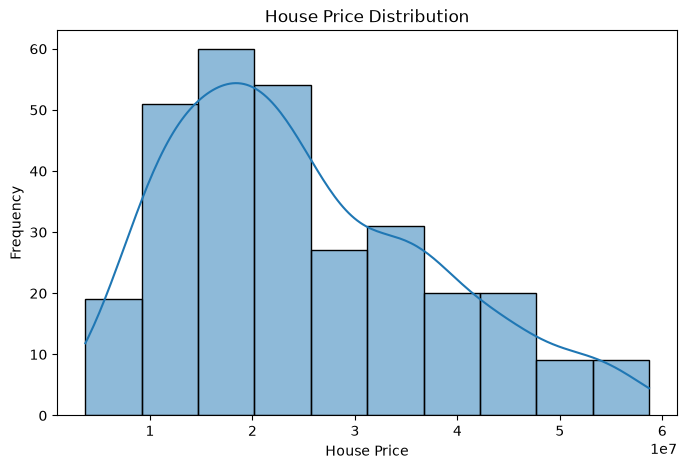

In [4]:
plt.figure(figsize=(8, 5))

sns.histplot(df["Price"], kde=True)

plt.title("House Price Distribution")
plt.xlabel("House Price")
plt.ylabel("Frequency")

plt.savefig("price_distribution.png")
plt.show()

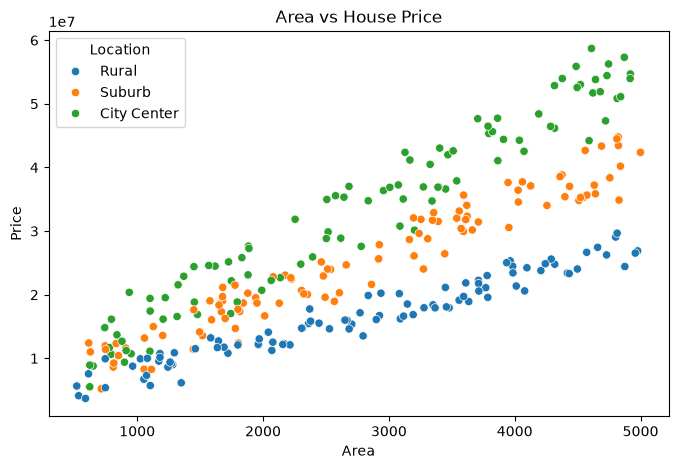

In [5]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Area",
    y="Price",
    hue="Location"
)

plt.title("Area vs House Price")
plt.savefig("area_vs_price.png")
plt.show()

Slope: 7771.692409121682
Intercept: 3436118.7918802416


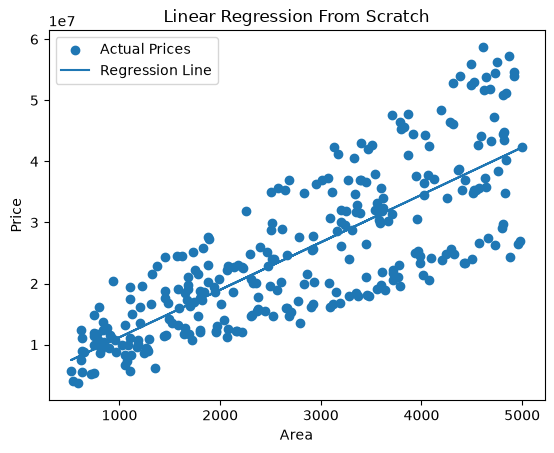

In [6]:
# Simple Linear Regression using Area

X = df["Area"].values
y = df["Price"].values

slope, intercept = np.polyfit(X, y, 1)

predicted_price = slope * X + intercept

print("Slope:", slope)
print("Intercept:", intercept)

plt.scatter(X, y, label="Actual Prices")
plt.plot(X, predicted_price, label="Regression Line")

plt.xlabel("Area")
plt.ylabel("Price")
plt.title("Linear Regression From Scratch")
plt.legend()
plt.show()

In [7]:
X = df.drop(columns=["Price", "Property_ID"])
y = df["Price"]

numeric_features = X.select_dtypes(
    include=["number"]
).columns

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"),
     numeric_features),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (240, 6)
Testing Data: (60, 6)


In [8]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    )
}

results = {}
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results[name] = {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    }

    trained_models[name] = pipeline

    print("\nModel:", name)
    print("MAE:", round(mae, 2))
    print("MSE:", round(mse, 2))
    print("RMSE:", round(rmse, 2))
    print("R2 Score:", round(r2, 4))


Model: Linear Regression
MAE: 2188736.34
MSE: 8454330868276.58
RMSE: 2907633.21
R2 Score: 0.9406

Model: Decision Tree
MAE: 2194416.67
MSE: 8203826666666.67
RMSE: 2864232.3
R2 Score: 0.9424

Model: Random Forest
MAE: 1482103.12
MSE: 3886718085986.98
RMSE: 1971476.12
R2 Score: 0.9727


In [9]:
results_df = pd.DataFrame(results).T

display(results_df)

best_model_name = results_df["R2 Score"].idxmax()

print("Best Model:", best_model_name)

,MAE,MSE,RMSE,R2 Score
Linear Regression,2.188736e+06,8.454331e+12,2.907633e+06,0.940637
Decision Tree,2.194417e+06,8.203827e+12,2.864232e+06,0.942396
Random Forest,1.482103e+06,3.886718e+12,1.971476e+06,0.972709


Best Model: Random Forest


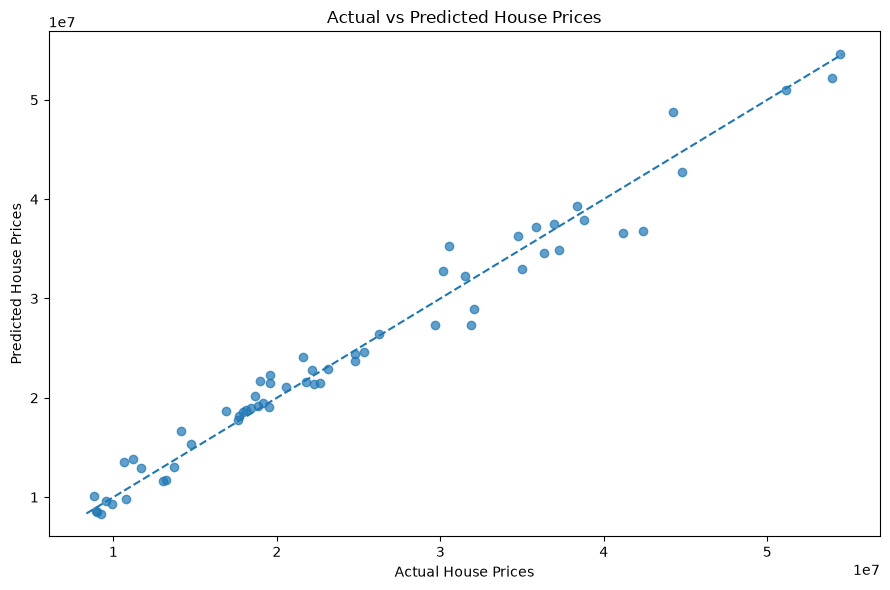

In [10]:
best_model = trained_models[best_model_name]

final_predictions = best_model.predict(X_test)

plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    final_predictions,
    alpha=0.7
)

minimum = min(y_test.min(), final_predictions.min())
maximum = max(y_test.max(), final_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")

plt.title("Actual vs Predicted House Prices")

plt.tight_layout()

plt.savefig(
    "predictions_vs_actual.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
sample_house = pd.DataFrame([{
    "Area": 2000,
    "Bedrooms": 3,
    "Bathrooms": 2,
    "Age": 5,
    "Location": "Suburb",
    "Property_Type": "House"
}])

predicted_price = best_model.predict(sample_house)

print(
    "Predicted House Price:",
    round(predicted_price[0], 2)
)

Predicted House Price: 19824337.5
